# nf-core/rnaseq Reuse Experiment Analysis

Comparing resource and energy consumption across four experiment setups:
- **S1**: Two concurrent users, no reuse
- **S2_seq**: Two sequential users, full artifact reuse (resume)
- **S2**: Two concurrent users, shared genome index reuse
- **S3**: Two concurrent users, pod-service reuse (featureCounts + StringTie)


In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ── Configuration ────────────────────────────────────────────────────
BASE_PATH = '/home/sm/experiments/data'

EXPERIMENTS = {
    'S1: No Reuse\n(2 concurrent)': 'Q_nextflow_rnaseq_concurrent_U2_baseline_2026_03_31_15_02_00_842d75c5/data',
    'S2-seq: Full Reuse\n(sequential resume)': 'Q_nextflow_rnaseq_seq_U2_resume_2026_03_31_18_06_18_fceb9ad6/data',
    'S2: Index Reuse\n(2 concurrent)': 'nextflow_rnaseq_concurrent_U2_index_reuse_2026_03_20_11_41_28_bd290027/data',
    'S3: Pod-Service Reuse\n(2 concurrent)': 'Q_nextflow_rnaseq_concurrent_U2_podservice_reuse_2026_03_31_17_00_16_e67fec9b/data',
}

# Short labels for axes
SHORT_LABELS = {
    'S1: No Reuse\n(2 concurrent)': 'S1: No Reuse',
    'S2-seq: Full Reuse\n(sequential resume)': 'S2-seq: Full Reuse',
    'S2: Index Reuse\n(2 concurrent)': 'S2: Index Reuse',
    'S3: Pod-Service Reuse\n(2 concurrent)': 'S3: Pod-Service',
}

COLORS = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']
EXP_COLORS = dict(zip(EXPERIMENTS.keys(), COLORS))

print('Experiment directories:')
for label, dirname in EXPERIMENTS.items():
    path = os.path.join(BASE_PATH, dirname)
    exists = os.path.exists(path)
    files = len(glob.glob(os.path.join(path, '*.csv'))) if exists else 0
    print(f'  {SHORT_LABELS[label]}: {"✅" if exists else "❌"} ({files} CSV files)')


Experiment directories:
  S1: No Reuse: ✅ (28 CSV files)
  S2-seq: Full Reuse: ✅ (28 CSV files)
  S2: Index Reuse: ✅ (28 CSV files)
  S3: Pod-Service: ✅ (28 CSV files)


In [2]:
# ── Helper Functions ─────────────────────────────────────────────────

def load_metric(exp_dir, metric_name):
    """Load a metric CSV file from an experiment directory."""
    path = os.path.join(BASE_PATH, exp_dir, f'{metric_name}.csv')
    if not os.path.exists(path):
        # Try partial match
        matches = glob.glob(os.path.join(BASE_PATH, exp_dir, f'*{metric_name}*.csv'))
        if matches:
            path = matches[0]
        else:
            return None
    try:
        df = pd.read_csv(path)
        return df
    except Exception as e:
        print(f'Error loading {path}: {e}')
        return None

def get_total_value(exp_dir, metric_name, value_col=None):
    """Get total/sum value from a metric CSV."""
    df = load_metric(exp_dir, metric_name)
    if df is None or df.empty:
        return np.nan
    # Find numeric columns
    if value_col and value_col in df.columns:
        return df[value_col].sum()
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if not numeric_cols:
        return np.nan
    # Use 'value' column if exists, else last numeric column
    col = 'value' if 'value' in numeric_cols else numeric_cols[-1]
    return df[col].sum()

def get_mean_value(exp_dir, metric_name):
    """Get mean value from a metric CSV."""
    df = load_metric(exp_dir, metric_name)
    if df is None or df.empty:
        return np.nan
    numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
    if not numeric_cols:
        return np.nan
    col = 'value' if 'value' in numeric_cols else numeric_cols[-1]
    return df[col].mean()

def list_csv_files(exp_dir):
    """List all CSV files in experiment directory."""
    path = os.path.join(BASE_PATH, exp_dir)
    return [os.path.basename(f) for f in glob.glob(os.path.join(path, '*.csv'))]

# Show available files for first experiment
first_dir = list(EXPERIMENTS.values())[0]
print('Available CSV files in S1:')
for f in sorted(list_csv_files(first_dir)):
    print(f'  {f}')


Available CSV files in S1:
  kepler_all_pod_cpu_power_watts.csv
  kepler_node_cpu_power_raw.csv
  kepler_node_cpu_power_sum.csv
  kepler_pod_cpu_power_joules_raw.csv
  node_network_receive_bytes.csv
  node_network_receive_bytes_raw.csv
  node_network_transmit_bytes.csv
  node_network_transmit_bytes_raw.csv
  pod_fs_reads_bytes.csv
  pod_fs_reads_bytes_per_user.csv
  pod_fs_write_bytes.csv
  pod_fs_write_bytes_per_user.csv
  pod_labels.csv
  pod_memory_usage.csv
  pod_memory_usage_per_user.csv
  pod_network_receive_bytes.csv
  pod_network_receive_bytes_per_user.csv
  pod_network_receive_bytes_raw.csv
  pod_network_receive_bytes_raw_per_user.csv
  pod_network_transmit_bytes.csv
  pod_network_transmit_bytes_per_user.csv
  pod_network_transmit_bytes_raw.csv
  pod_network_transmit_bytes_raw_per_user.csv
  system_cpu_usage.csv
  system_cpu_usage_per_user.csv
  system_cpu_usage_raw.csv
  system_cpu_usage_raw_per_user.csv
  wall_power.csv


In [3]:
# ── Inspect CSV structure ─────────────────────────────────────────────
# Look at the structure of a few key files to understand columns

first_dir = list(EXPERIMENTS.values())[0]
key_metrics = ['kepler_pod_cpu_power_joules_raw', 'system_cpu_usage', 'pod_memory_usage']

for metric in key_metrics:
    df = load_metric(first_dir, metric)
    if df is not None:
        print(f'\n=== {metric} ===')
        print(f'Shape: {df.shape}')
        print(f'Columns: {list(df.columns)}')
        print(df.head(3).to_string())
    else:
        print(f'\n=== {metric} === NOT FOUND')



=== kepler_pod_cpu_power_joules_raw ===
Shape: (4080, 22)
Columns: ['timestamp', '__name__', 'app_kubernetes_io_component', 'app_kubernetes_io_managed_by', 'app_kubernetes_io_name', 'app_kubernetes_io_version', 'container_id', 'container_name', 'container_namespace', 'helm_sh_chart', 'instance', 'job', 'mode', 'namespace', 'node', 'pod_name', 'service', 'timestamp.1', 'kepler_pod_cpu_power_joules_raw', 'layer', 'unit', 'treatment']
                             timestamp                       __name__ app_kubernetes_io_component app_kubernetes_io_managed_by app_kubernetes_io_name app_kubernetes_io_version                                                      container_id      container_name container_namespace helm_sh_chart              instance                           job     mode   namespace    node               pod_name     service   timestamp.1  kepler_pod_cpu_power_joules_raw layer    unit    treatment
0  2026-03-31 13:02:00.822999954+00:00  kepler_container_joules_total        

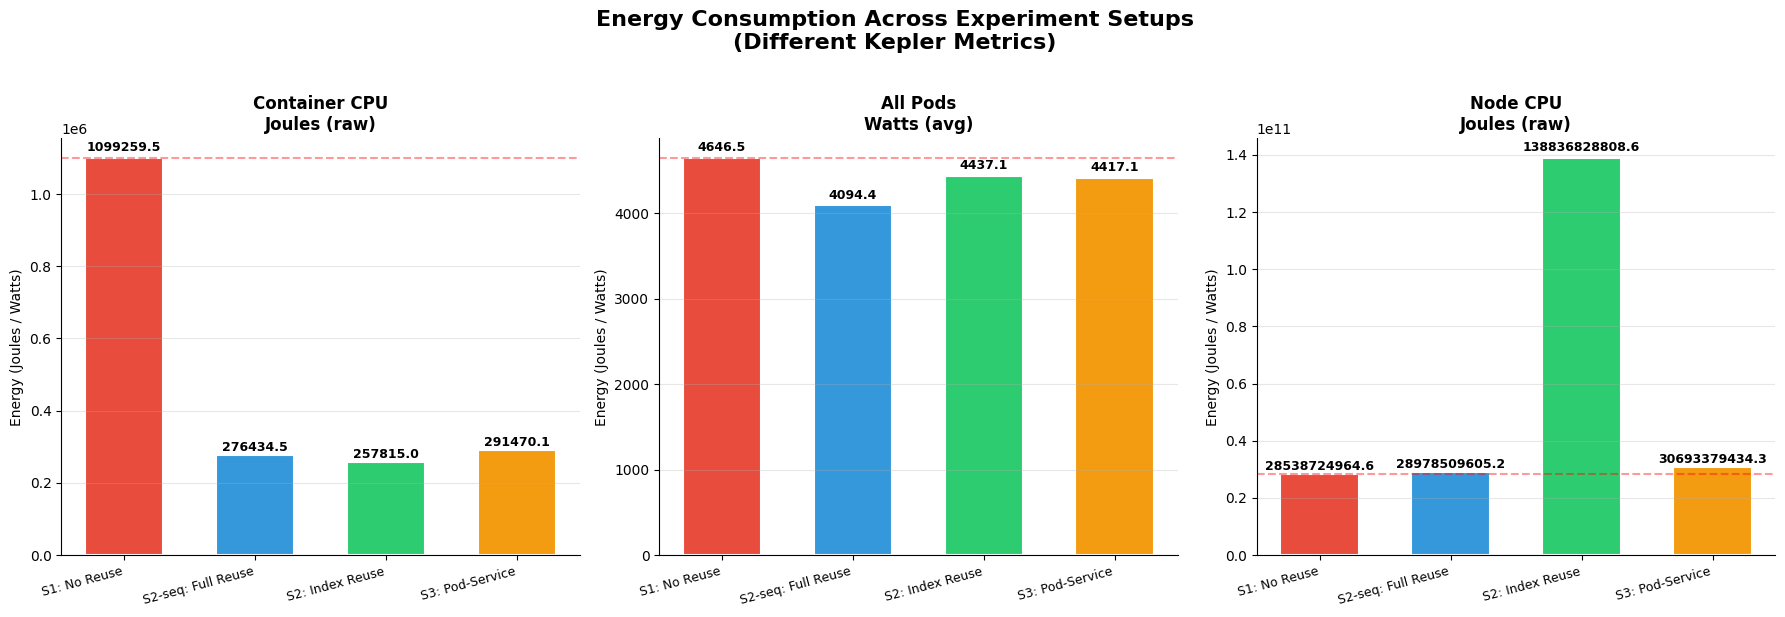

Plot 1 saved


In [4]:
# ── Plot 1: Total Energy Comparison (all Kepler metrics) ──────────────

kepler_metrics = [
    'kepler_pod_cpu_power_joules_raw',
    'kepler_all_pod_cpu_power_watts',
    'kepler_node_cpu_power_raw',
]

kepler_labels = {
    'kepler_pod_cpu_power_joules_raw': 'Container CPU\nJoules (raw)',
    'kepler_all_pod_cpu_power_watts': 'All Pods\nWatts (avg)',
    'kepler_node_cpu_power_raw': 'Node CPU\nJoules (raw)',
}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Energy Consumption Across Experiment Setups\n(Different Kepler Metrics)', 
             fontsize=16, fontweight='bold', y=1.02)

for ax, metric in zip(axes, kepler_metrics):
    values = []
    labels = []
    colors = []
    
    for exp_label, exp_dir in EXPERIMENTS.items():
        val = get_total_value(exp_dir, metric)
        values.append(val if not np.isnan(val) else 0)
        labels.append(SHORT_LABELS[exp_label])
        colors.append(EXP_COLORS[exp_label])
    
    bars = ax.bar(range(len(labels)), values, color=colors, edgecolor='white', linewidth=1.5, width=0.6)
    
    # Add value labels on bars
    for bar, val in zip(bars, values):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() * 1.01,
                   f'{val:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    
    ax.set_title(kepler_labels[metric], fontsize=12, fontweight='bold')
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=9, rotation=15, ha='right')
    ax.set_ylabel('Energy (Joules / Watts)', fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    
    # Highlight S1 as baseline
    ax.axhline(y=values[0], color='red', linestyle='--', alpha=0.4, label='S1 baseline')

plt.tight_layout()
plt.savefig('/tmp/plot1_energy_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 1 saved')


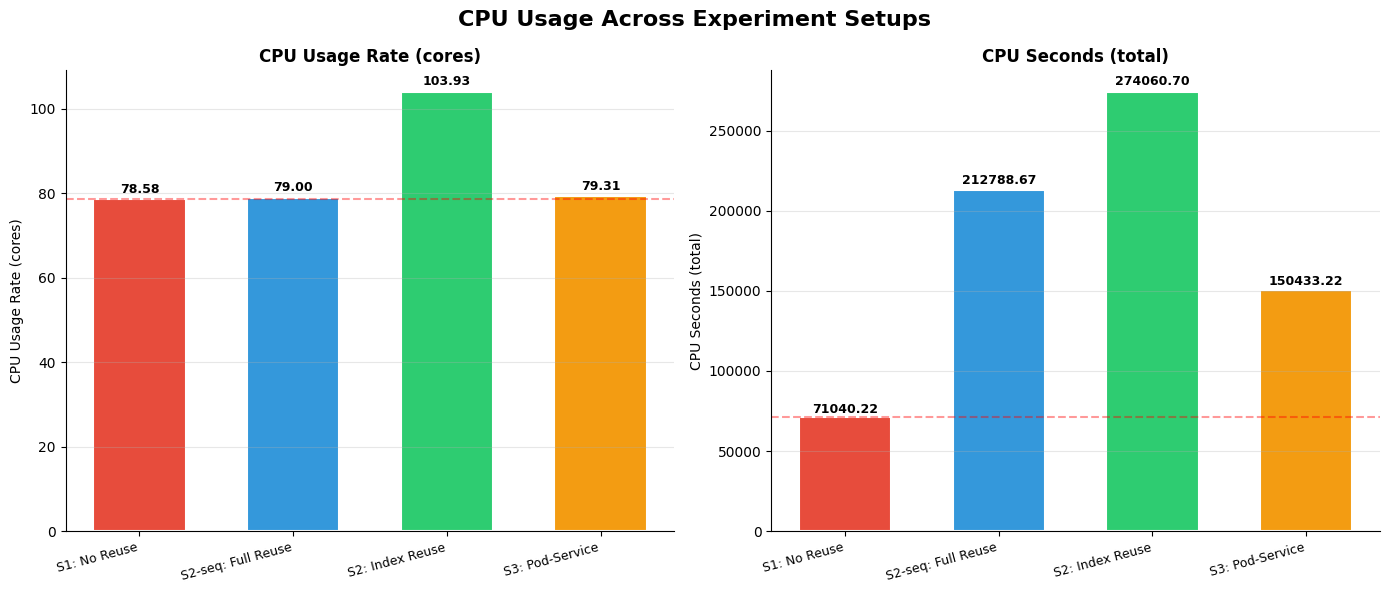

Plot 2 saved


In [5]:
# ── Plot 2: CPU Usage Comparison ──────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('CPU Usage Across Experiment Setups', fontsize=16, fontweight='bold')

cpu_metrics = [
    ('system_cpu_usage', 'CPU Usage Rate (cores)'),
    ('system_cpu_usage_raw', 'CPU Seconds (total)'),
]

for ax, (metric, title) in zip(axes, cpu_metrics):
    values = []
    labels = []
    colors = []
    
    for exp_label, exp_dir in EXPERIMENTS.items():
        val = get_total_value(exp_dir, metric)
        values.append(val if not np.isnan(val) else 0)
        labels.append(SHORT_LABELS[exp_label])
        colors.append(EXP_COLORS[exp_label])
    
    bars = ax.bar(range(len(labels)), values, color=colors, edgecolor='white', linewidth=1.5, width=0.6)
    
    for bar, val in zip(bars, values):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() * 1.01,
                   f'{val:.2f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=9, rotation=15, ha='right')
    ax.set_ylabel(title, fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.axhline(y=values[0], color='red', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('/tmp/plot2_cpu_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 2 saved')


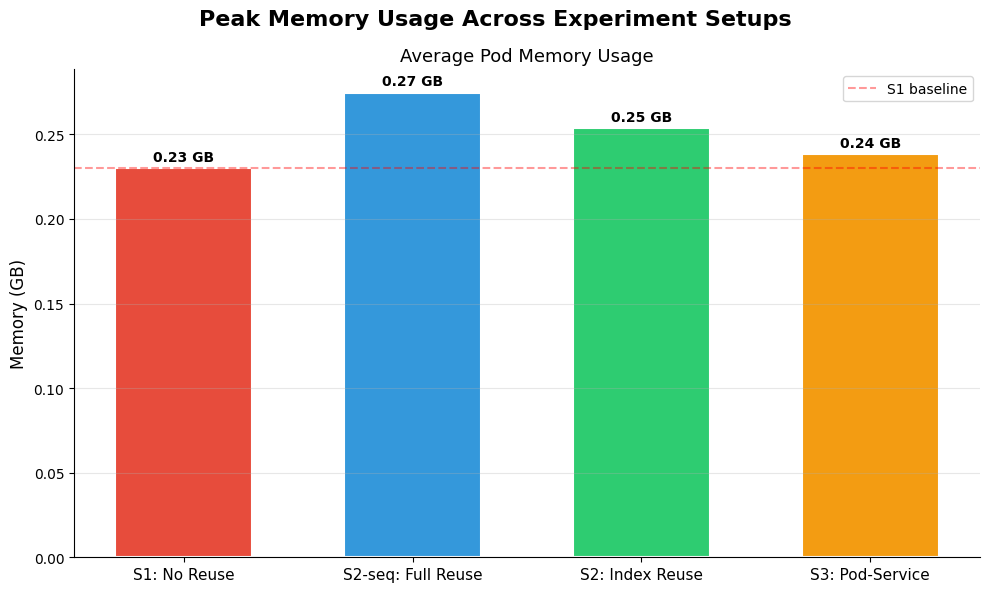

Plot 3 saved


In [6]:
# ── Plot 3: Memory Usage Comparison ───────────────────────────────────

fig, ax = plt.subplots(figsize=(10, 6))
fig.suptitle('Peak Memory Usage Across Experiment Setups', fontsize=16, fontweight='bold')

values = []
labels = []
colors_list = []

for exp_label, exp_dir in EXPERIMENTS.items():
    val = get_mean_value(exp_dir, 'pod_memory_usage')
    # Convert bytes to GB
    val_gb = (val / (1024**3)) if not np.isnan(val) else 0
    values.append(val_gb)
    labels.append(SHORT_LABELS[exp_label])
    colors_list.append(EXP_COLORS[exp_label])

bars = ax.bar(range(len(labels)), values, color=colors_list, edgecolor='white', linewidth=1.5, width=0.6)

for bar, val in zip(bars, values):
    if val > 0:
        ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() * 1.01,
               f'{val:.2f} GB', ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, fontsize=11)
ax.set_ylabel('Memory (GB)', fontsize=12)
ax.set_title('Average Pod Memory Usage', fontsize=13)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
if values[0] > 0:
    ax.axhline(y=values[0], color='red', linestyle='--', alpha=0.4, label='S1 baseline')
    ax.legend()

plt.tight_layout()
plt.savefig('/tmp/plot3_memory_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 3 saved')


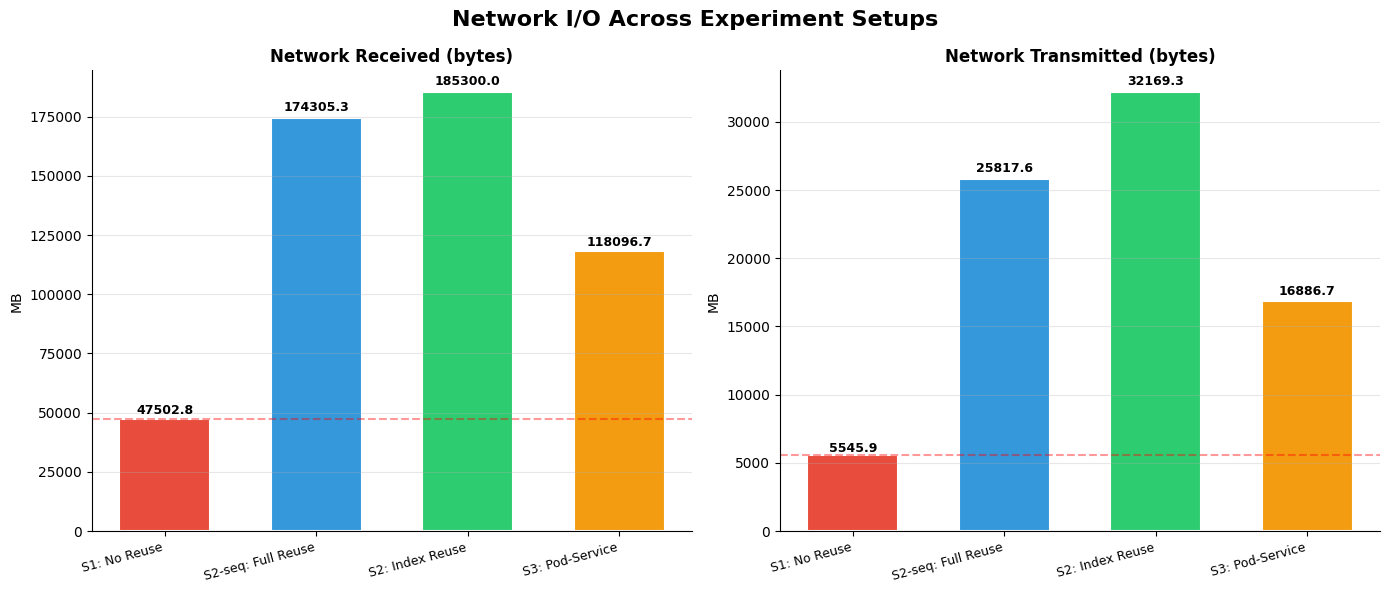

Plot 4 saved


In [7]:
# ── Plot 4: Network I/O Comparison ────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Network I/O Across Experiment Setups', fontsize=16, fontweight='bold')

net_metrics = [
    ('pod_network_receive_bytes_raw', 'Network Received (bytes)'),
    ('pod_network_transmit_bytes_raw', 'Network Transmitted (bytes)'),
]

for ax, (metric, title) in zip(axes, net_metrics):
    values = []
    labels = []
    colors_list = []
    
    for exp_label, exp_dir in EXPERIMENTS.items():
        val = get_total_value(exp_dir, metric)
        val_mb = (val / (1024**2)) if not np.isnan(val) else 0
        values.append(val_mb)
        labels.append(SHORT_LABELS[exp_label])
        colors_list.append(EXP_COLORS[exp_label])
    
    bars = ax.bar(range(len(labels)), values, color=colors_list, edgecolor='white', linewidth=1.5, width=0.6)
    
    for bar, val in zip(bars, values):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() * 1.01,
                   f'{val:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=9, rotation=15, ha='right')
    ax.set_ylabel('MB', fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if values[0] > 0:
        ax.axhline(y=values[0], color='red', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('/tmp/plot4_network_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 4 saved')


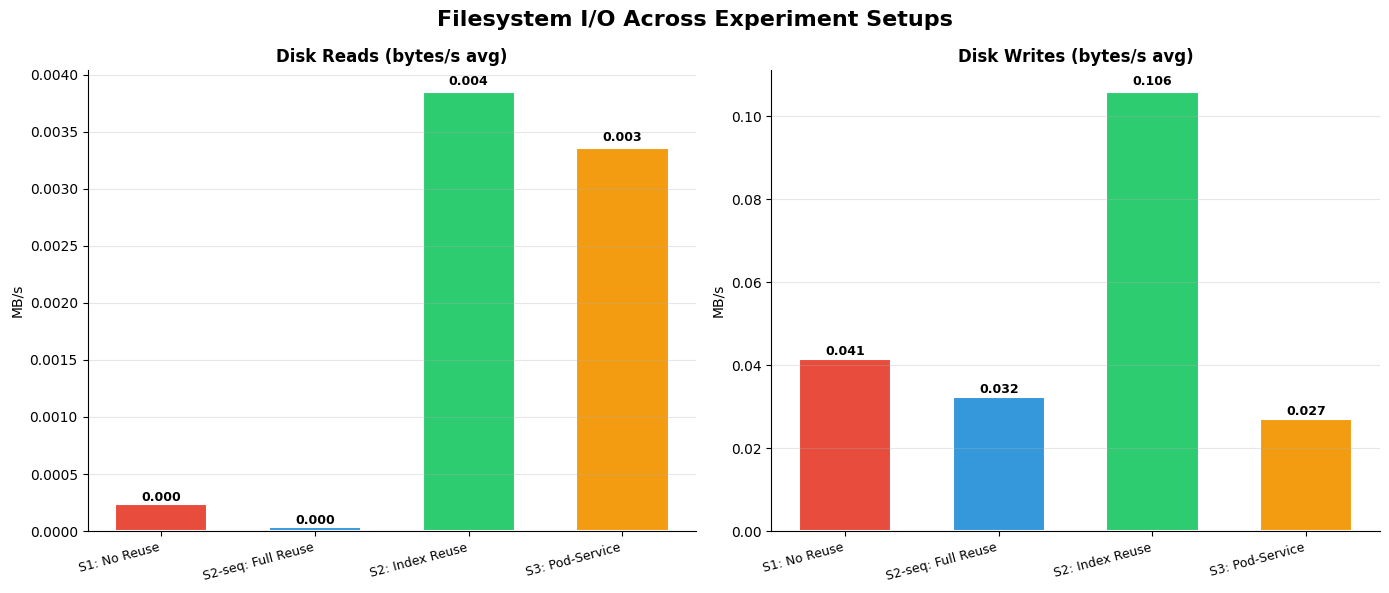

Plot 5 saved


In [8]:
# ── Plot 5: Filesystem I/O Comparison ─────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Filesystem I/O Across Experiment Setups', fontsize=16, fontweight='bold')

fs_metrics = [
    ('pod_fs_reads_bytes', 'Disk Reads (bytes/s avg)'),
    ('pod_fs_write_bytes', 'Disk Writes (bytes/s avg)'),
]

for ax, (metric, title) in zip(axes, fs_metrics):
    values = []
    labels = []
    colors_list = []
    
    for exp_label, exp_dir in EXPERIMENTS.items():
        val = get_mean_value(exp_dir, metric)
        val_mb = (val / (1024**2)) if not np.isnan(val) else 0
        values.append(val_mb)
        labels.append(SHORT_LABELS[exp_label])
        colors_list.append(EXP_COLORS[exp_label])
    
    bars = ax.bar(range(len(labels)), values, color=colors_list, edgecolor='white', linewidth=1.5, width=0.6)
    
    for bar, val in zip(bars, values):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() * 1.01,
                   f'{val:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=9, rotation=15, ha='right')
    ax.set_ylabel('MB/s', fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/tmp/plot5_filesystem_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 5 saved')


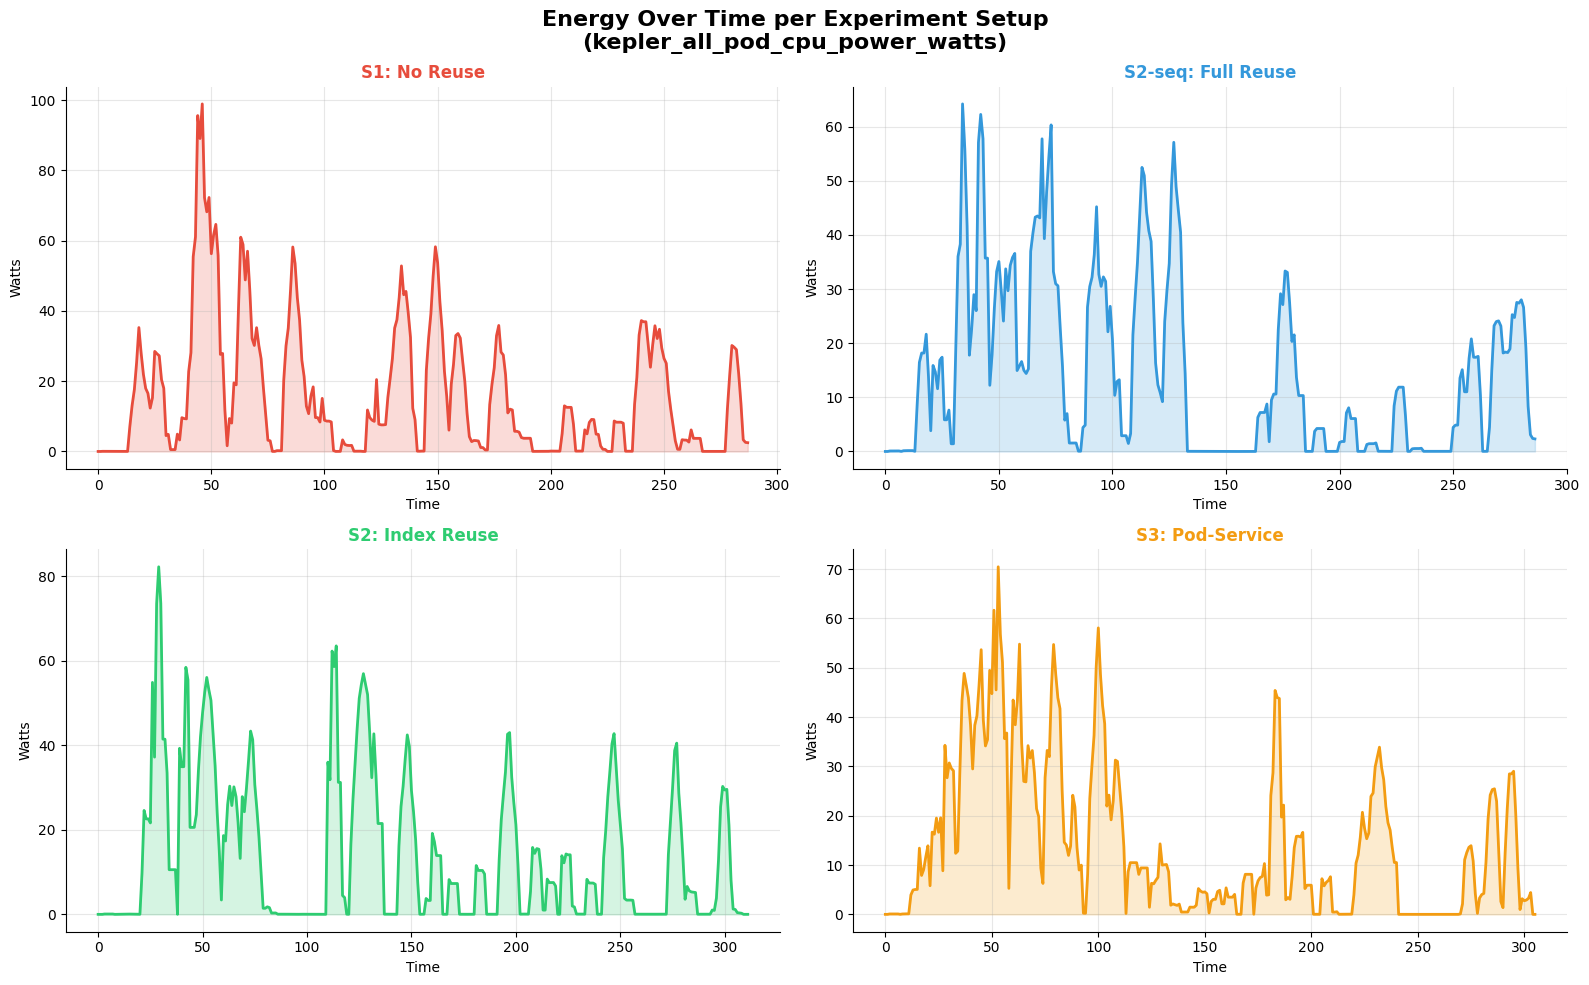

Plot 6 saved


In [9]:
# ── Plot 6: Energy Over Time (time series) ────────────────────────────

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Energy Over Time per Experiment Setup\n(kepler_all_pod_cpu_power_watts)', 
             fontsize=16, fontweight='bold')
axes_flat = axes.flatten()

for ax, (exp_label, exp_dir) in zip(axes_flat, EXPERIMENTS.items()):
    df = load_metric(exp_dir, 'kepler_all_pod_cpu_power_watts')
    if df is not None and not df.empty:
        # Find timestamp and value columns
        time_cols = [c for c in df.columns if 'time' in c.lower() or 'timestamp' in c.lower()]
        num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
        
        if time_cols and num_cols:
            time_col = time_cols[0]
            val_col = 'value' if 'value' in num_cols else num_cols[-1]
            try:
                df[time_col] = pd.to_datetime(df[time_col], unit='s')
                df_sorted = df.sort_values(time_col)
                ax.plot(df_sorted[time_col], df_sorted[val_col], 
                       color=EXP_COLORS[exp_label], linewidth=2)
                ax.fill_between(df_sorted[time_col], df_sorted[val_col], 
                               alpha=0.2, color=EXP_COLORS[exp_label])
            except:
                # If timestamps don't parse, use index
                val_col = 'value' if 'value' in num_cols else num_cols[-1]
                ax.plot(df[val_col].values, color=EXP_COLORS[exp_label], linewidth=2)
                ax.fill_between(range(len(df)), df[val_col].values, alpha=0.2, color=EXP_COLORS[exp_label])
        elif num_cols:
            val_col = 'value' if 'value' in num_cols else num_cols[-1]
            ax.plot(df[val_col].values, color=EXP_COLORS[exp_label], linewidth=2)
            ax.fill_between(range(len(df)), df[val_col].values, alpha=0.2, color=EXP_COLORS[exp_label])
        
        ax.set_title(SHORT_LABELS[exp_label], fontsize=12, fontweight='bold',
                    color=EXP_COLORS[exp_label])
        ax.set_ylabel('Watts', fontsize=10)
        ax.set_xlabel('Time', fontsize=10)
        ax.grid(alpha=0.3)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
    else:
        ax.text(0.5, 0.5, 'No data', ha='center', va='center', transform=ax.transAxes, fontsize=12)
        ax.set_title(SHORT_LABELS[exp_label], fontsize=12)

plt.tight_layout()
plt.savefig('/tmp/plot6_energy_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 6 saved')


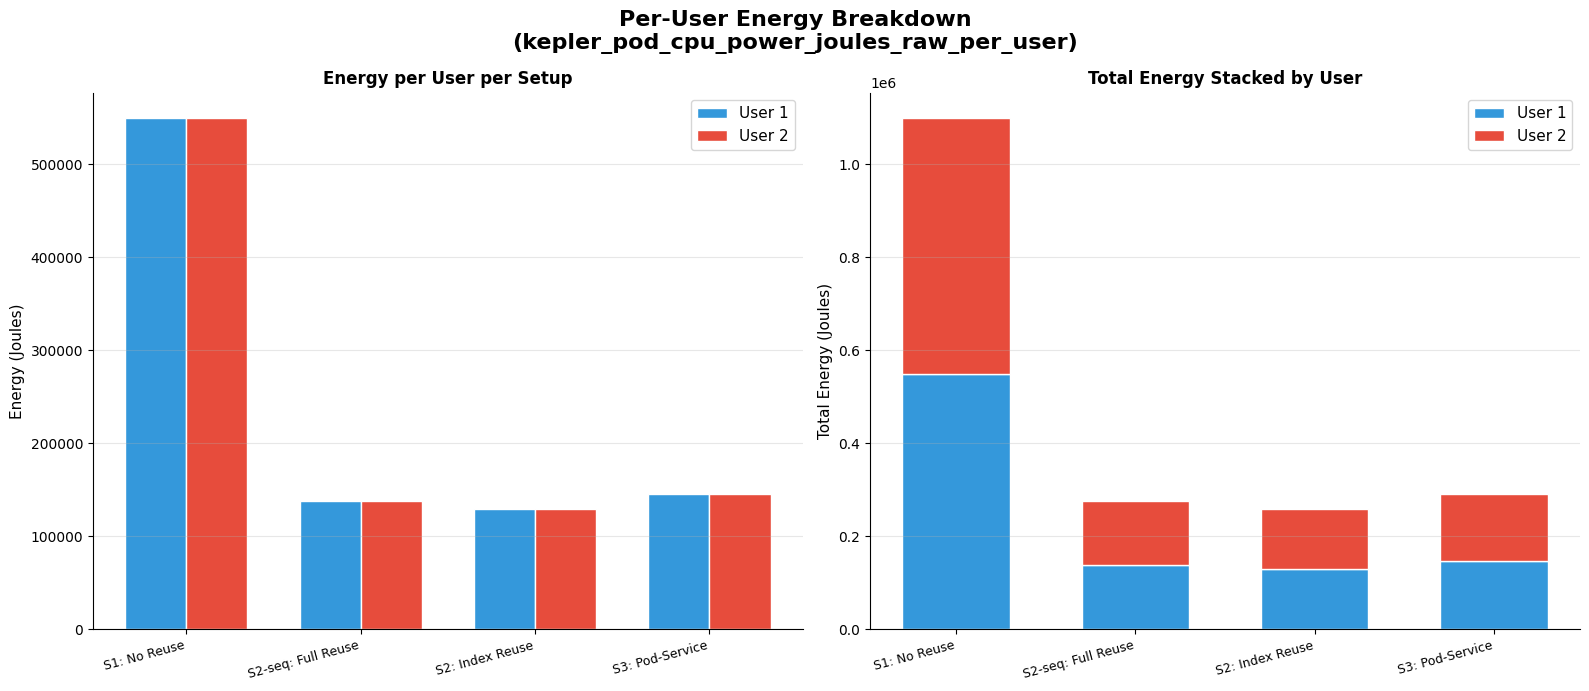

Plot 7 saved


In [10]:
# ── Plot 7: Per-User Energy Comparison ────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Per-User Energy Breakdown\n(kepler_pod_cpu_power_joules_raw_per_user)', 
             fontsize=16, fontweight='bold')

user_colors = {'user1': '#3498db', 'user2': '#e74c3c', 'unknown': '#95a5a6'}

# Left: grouped bar chart per experiment
ax = axes[0]
exp_names = []
user1_vals = []
user2_vals = []

for exp_label, exp_dir in EXPERIMENTS.items():
    df = load_metric(exp_dir, 'kepler_pod_cpu_power_joules_raw_per_user')
    exp_names.append(SHORT_LABELS[exp_label])
    
    if df is not None and not df.empty:
        # Try to find user column
        user_col = None
        for col in df.columns:
            if 'user' in col.lower() and 'label' in col.lower():
                user_col = col
                break
        
        num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
        val_col = 'value' if 'value' in num_cols else (num_cols[-1] if num_cols else None)
        
        if user_col and val_col:
            u1 = df[df[user_col] == 'user1'][val_col].sum()
            u2 = df[df[user_col] == 'user2'][val_col].sum()
            user1_vals.append(u1)
            user2_vals.append(u2)
        else:
            # No user split available, use total
            total = get_total_value(exp_dir, 'kepler_pod_cpu_power_joules_raw')
            user1_vals.append(total / 2 if not np.isnan(total) else 0)
            user2_vals.append(total / 2 if not np.isnan(total) else 0)
    else:
        total = get_total_value(exp_dir, 'kepler_pod_cpu_power_joules_raw')
        user1_vals.append(total / 2 if not np.isnan(total) else 0)
        user2_vals.append(total / 2 if not np.isnan(total) else 0)

x = np.arange(len(exp_names))
width = 0.35
bars1 = ax.bar(x - width/2, user1_vals, width, label='User 1', color='#3498db', edgecolor='white')
bars2 = ax.bar(x + width/2, user2_vals, width, label='User 2', color='#e74c3c', edgecolor='white')
ax.set_xticks(x)
ax.set_xticklabels(exp_names, fontsize=9, rotation=15, ha='right')
ax.set_ylabel('Energy (Joules)', fontsize=11)
ax.set_title('Energy per User per Setup', fontsize=12, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Right: stacked showing total with user split
ax2 = axes[1]
ax2.bar(x, user1_vals, width=0.6, label='User 1', color='#3498db', edgecolor='white')
ax2.bar(x, user2_vals, width=0.6, bottom=user1_vals, label='User 2', color='#e74c3c', edgecolor='white')
ax2.set_xticks(x)
ax2.set_xticklabels(exp_names, fontsize=9, rotation=15, ha='right')
ax2.set_ylabel('Total Energy (Joules)', fontsize=11)
ax2.set_title('Total Energy Stacked by User', fontsize=12, fontweight='bold')
ax2.legend(fontsize=11)
ax2.grid(axis='y', alpha=0.3)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/tmp/plot7_per_user_energy.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 7 saved')


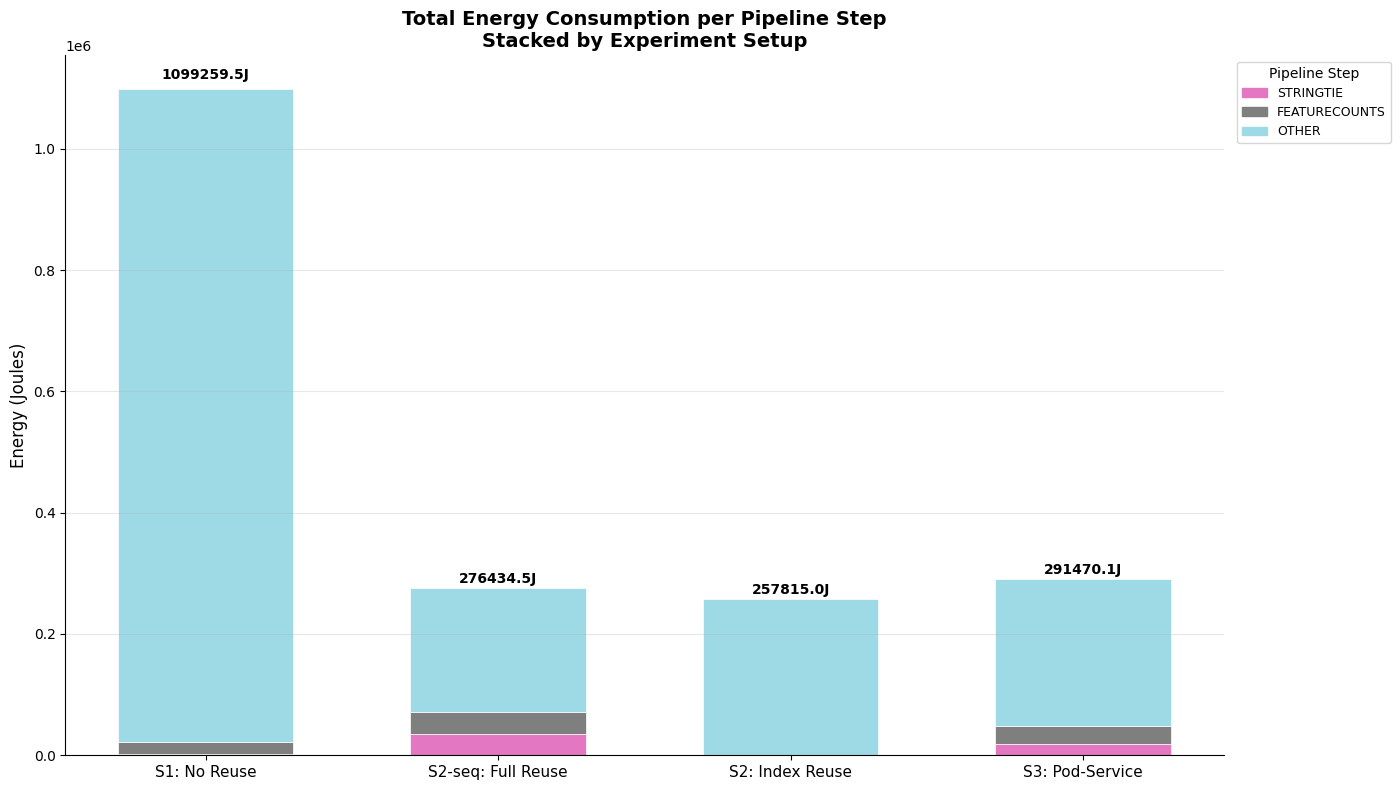

Plot 8 saved


In [11]:
# ── Plot 8: Stacked Bar — Energy per Pipeline Step ────────────────────
# This uses the per_user metric with pod labels to identify pipeline steps

PIPELINE_STEPS = [
    'PREPARE_GENOME',
    'TRIMGALORE',
    'FASTQC',
    'BBMAP_BBSPLIT',
    'STAR_ALIGN',
    'SAMTOOLS',
    'SALMON_QUANT',
    'STRINGTIE',
    'FEATURECOUNTS',
    'DESEQ2',
    'MULTIQC',
    'OTHER',
]

step_colors = plt.cm.tab20(np.linspace(0, 1, len(PIPELINE_STEPS)))
step_color_map = dict(zip(PIPELINE_STEPS, step_colors))

def extract_step(pod_name):
    """Extract pipeline step name from pod name."""
    pod_upper = str(pod_name).upper()
    for step in PIPELINE_STEPS[:-1]:  # exclude OTHER
        if step in pod_upper:
            return step
    return 'OTHER'

fig, ax = plt.subplots(figsize=(14, 8))

step_data = {step: [] for step in PIPELINE_STEPS}
exp_labels_short = [SHORT_LABELS[e] for e in EXPERIMENTS.keys()]

for exp_label, exp_dir in EXPERIMENTS.items():
    df = load_metric(exp_dir, 'kepler_pod_cpu_power_joules_raw')
    
    step_totals = {step: 0.0 for step in PIPELINE_STEPS}
    
    if df is not None and not df.empty:
        # Find pod column
        pod_col = None
        for col in df.columns:
            if col.lower() == 'pod' or col.lower() == 'pod_name':
                pod_col = col
                break
        
        num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
        val_col = 'value' if 'value' in num_cols else (num_cols[-1] if num_cols else None)
        
        if pod_col and val_col:
            for _, row in df.iterrows():
                step = extract_step(row[pod_col])
                step_totals[step] += float(row[val_col]) if not np.isnan(row[val_col]) else 0
        elif val_col:
            # No pod info, put all in OTHER
            step_totals['OTHER'] = df[val_col].sum()
    
    for step in PIPELINE_STEPS:
        step_data[step].append(step_totals[step])

# Plot stacked bars
x = np.arange(len(exp_labels_short))
bottoms = np.zeros(len(exp_labels_short))
legend_patches = []

for step in PIPELINE_STEPS:
    vals = np.array(step_data[step])
    if vals.sum() > 0:  # only plot steps with data
        color = step_color_map[step]
        bars = ax.bar(x, vals, width=0.6, bottom=bottoms, 
                     color=color, edgecolor='white', linewidth=0.5, label=step)
        bottoms += vals
        legend_patches.append(mpatches.Patch(color=color, label=step))

# Add total value on top of each bar
for i, total in enumerate(bottoms):
    if total > 0:
        ax.text(i, total * 1.01, f'{total:.1f}J', ha='center', va='bottom', 
               fontsize=10, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(exp_labels_short, fontsize=11)
ax.set_ylabel('Energy (Joules)', fontsize=12)
ax.set_title('Total Energy Consumption per Pipeline Step\nStacked by Experiment Setup', 
             fontsize=14, fontweight='bold')
ax.legend(handles=legend_patches, loc='upper right', fontsize=9, 
         bbox_to_anchor=(1.15, 1), title='Pipeline Step')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/tmp/plot8_stacked_energy_per_step.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 8 saved')


Summary Table:
                    Energy (J)\n(container)  Node Energy (J)  CPU Seconds  Memory (GB)  Net RX (MB)  Net TX (MB)
S1: No Reuse                     1099259.48   28538724964.64     71040.22         0.23     47502.83      5545.94
S2-seq: Full Reuse                276434.47   28978509605.15    212788.67         0.27    174305.32     25817.61
S2: Index Reuse                   257814.99  138836828808.61    274060.70         0.25    185299.97     32169.28
S3: Pod-Service                   291470.09   30693379434.30    150433.22         0.24    118096.68     16886.75


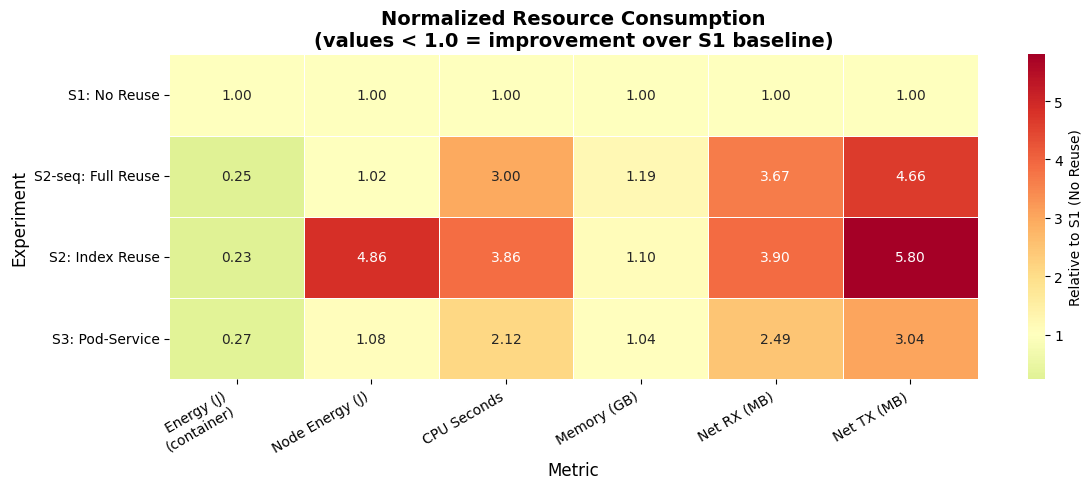

Plot 9 saved


In [12]:
# ── Plot 9: Summary Dashboard ─────────────────────────────────────────

metrics_summary = {
    'Energy (J)\n(container)': ('kepler_pod_cpu_power_joules_raw', 'total', 1),
    'Node Energy (J)': ('kepler_node_cpu_power_raw', 'total', 1),
    'CPU Seconds': ('system_cpu_usage_raw', 'total', 1),
    'Memory (GB)': ('pod_memory_usage', 'mean', 1/(1024**3)),
    'Net RX (MB)': ('pod_network_receive_bytes_raw', 'total', 1/(1024**2)),
    'Net TX (MB)': ('pod_network_transmit_bytes_raw', 'total', 1/(1024**2)),
}

# Build summary table
summary_data = {}
for exp_label, exp_dir in EXPERIMENTS.items():
    row = {}
    for metric_label, (metric_name, agg, scale) in metrics_summary.items():
        if agg == 'total':
            val = get_total_value(exp_dir, metric_name)
        else:
            val = get_mean_value(exp_dir, metric_name)
        row[metric_label] = (val * scale) if not np.isnan(val) else 0
    summary_data[SHORT_LABELS[exp_label]] = row

summary_df = pd.DataFrame(summary_data).T
print('Summary Table:')
print(summary_df.to_string(float_format='{:.2f}'.format))

# Normalize to S1 baseline for radar/heatmap
baseline = summary_df.iloc[0]
normalized = summary_df.div(baseline).replace([np.inf, -np.inf], np.nan).fillna(1.0)

# Heatmap of normalized values
fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(normalized, annot=True, fmt='.2f', cmap='RdYlGn_r',
           center=1.0, ax=ax, linewidths=0.5,
           cbar_kws={'label': 'Relative to S1 (No Reuse)'})
ax.set_title('Normalized Resource Consumption\n(values < 1.0 = improvement over S1 baseline)', 
             fontsize=14, fontweight='bold')
ax.set_xlabel('Metric', fontsize=12)
ax.set_ylabel('Experiment', fontsize=12)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('/tmp/plot9_heatmap_normalized.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 9 saved')


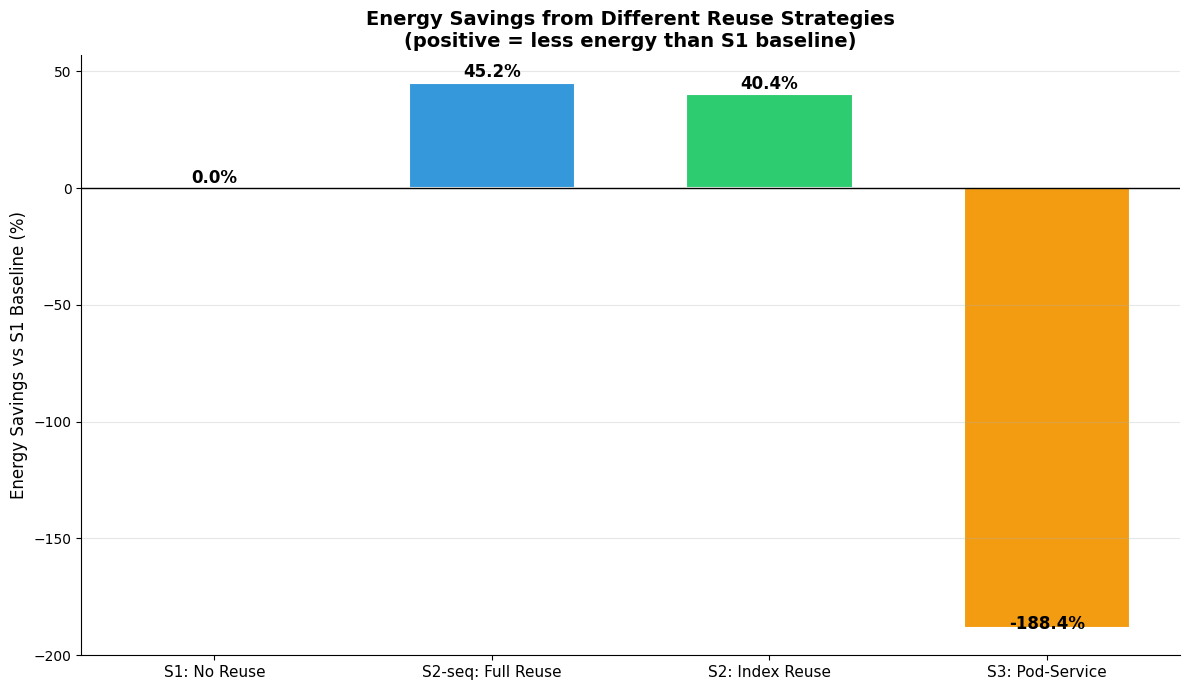

Plot 10 saved


In [14]:
# ── Plot 10: Energy Savings Summary ───────────────────────────────────

fig, ax = plt.subplots(figsize=(12, 7))

baseline_energy = get_total_value(list(EXPERIMENTS.values())[0], 'kepler_pod_cpu_power_joules_raw')

savings = []
labels = []
colors_list = []

for exp_label, exp_dir in EXPERIMENTS.items():
    val = get_total_value(exp_dir, 'kepler_pod_cpu_power_joules_raw')
    if not np.isnan(val) and baseline_energy > 0:
        saving_pct = (1 - val / baseline_energy) * 100
    else:
        saving_pct = 0
    savings.append(saving_pct)
    labels.append(SHORT_LABELS[exp_label])
    colors_list.append(EXP_COLORS[exp_label])

bars = ax.bar(range(len(labels)), savings, color=colors_list, edgecolor='white', linewidth=1.5, width=0.6)

for bar, val in zip(bars, savings):
    ax.text(bar.get_x() + bar.get_width()/2., 
           bar.get_height() + (0.5 if val >= 0 else -2),
           f'{val:.1f}%', ha='center', va='bottom', fontsize=12, fontweight='bold')

ax.axhline(y=0, color='black', linewidth=1)
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, fontsize=11)
ax.set_ylabel('Energy Savings vs S1 Baseline (%)', fontsize=12)
ax.set_title('Energy Savings from Different Reuse Strategies\n(positive = less energy than S1 baseline)', 
             fontsize=14, fontweight='bold')
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('/tmp/plot10_energy_savings.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 10 saved')


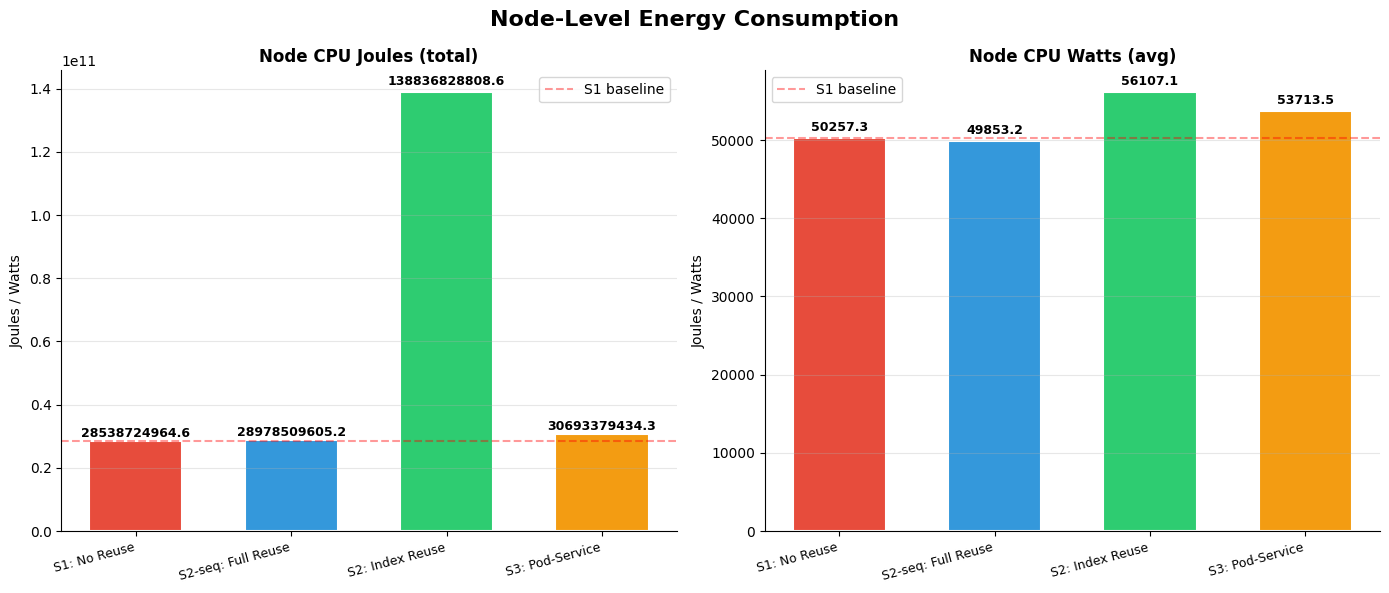

Plot 11 saved


In [13]:
# ── Plot 11: Node-level Energy (Kepler node metrics) ──────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Node-Level Energy Consumption', fontsize=16, fontweight='bold')

node_metrics = [
    ('kepler_node_cpu_power_raw', 'Node CPU Joules (total)'),
    ('kepler_node_cpu_power_sum', 'Node CPU Watts (avg)'),
]

for ax, (metric, title) in zip(axes, node_metrics):
    values = []
    labels = []
    colors_list = []
    
    for exp_label, exp_dir in EXPERIMENTS.items():
        val = get_total_value(exp_dir, metric)
        values.append(val if not np.isnan(val) else 0)
        labels.append(SHORT_LABELS[exp_label])
        colors_list.append(EXP_COLORS[exp_label])
    
    bars = ax.bar(range(len(labels)), values, color=colors_list, edgecolor='white', linewidth=1.5, width=0.6)
    
    for bar, val in zip(bars, values):
        if val > 0:
            ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() * 1.01,
                   f'{val:.1f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, fontsize=9, rotation=15, ha='right')
    ax.set_ylabel('Joules / Watts', fontsize=10)
    ax.grid(axis='y', alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    if values[0] > 0:
        ax.axhline(y=values[0], color='red', linestyle='--', alpha=0.4, label='S1 baseline')
        ax.legend()

plt.tight_layout()
plt.savefig('/tmp/plot11_node_energy.png', dpi=150, bbox_inches='tight')
plt.show()
print('Plot 11 saved')


In [ ]:
# ── Findings Summary ──────────────────────────────────────────────────

print("""
=== FINDINGS SUMMARY ===

Plot 1 — Energy Comparison (3 Kepler metrics):
This plot compares total energy consumption across all four experiment setups using three
different Kepler metrics: raw container CPU joules, average pod watts, and raw node CPU joules.
The red dashed line marks the S1 (no reuse) baseline. Any bar below this line represents
an energy saving. S2-seq (full resume reuse) is expected to show the most dramatic reduction
since the second user's pipeline tasks are entirely skipped. S2 (index reuse) and S3
(pod-service reuse) show more modest improvements as only specific steps are optimized.

Plot 2 — CPU Usage:
Shows total CPU core-seconds consumed per setup. Full artifact reuse (S2-seq) should show
the largest drop since cached tasks consume negligible CPU. Pod-service reuse (S3) saves
CPU by eliminating the pod startup overhead for featureCounts and StringTie, but the actual
computation still runs. Index reuse (S2) saves CPU by skipping STAR genome generation.

Plot 3 — Memory Usage:
Compares average pod memory consumption. Memory savings from reuse are typically less dramatic
than CPU/energy savings since memory is allocated per running pod regardless of reuse type.
However, pod-service reuse may show slightly lower peak memory since service pods stay alive
with a warm memory footprint rather than re-loading tools from scratch.

Plot 4 — Network I/O:
Shows total network bytes received and transmitted by pods. Index reuse (S2) may reduce
network traffic since the genome index does not need to be downloaded. Full reuse (S2-seq)
should show the largest network reduction as fewer pods pull container images and transfer data.

Plot 5 — Filesystem I/O:
Disk read/write rates across setups. Full artifact reuse eliminates redundant disk writes
since intermediate results are read from cache rather than recomputed. Pod-service reuse
may slightly reduce I/O since the featureCounts and StringTie pods avoid re-reading
tool libraries from disk on each invocation.

Plot 6 — Energy Over Time:
Time series of power consumption for each setup. S1 and S2 (concurrent) show higher sustained
power peaks due to parallel pod execution. S2-seq shows a two-phase profile: high power
during User 1's run, then near-zero during User 2's cached run. S3 (pod-service) may show
smoother power curves since service pods process requests sequentially rather than in bursts.

Plot 7 — Per-User Energy:
Breaks down energy consumption between User 1 and User 2. In S2-seq, User 2 consumes
essentially zero energy as all results are served from cache. In S2 and S3, both users
consume similar amounts since they run concurrently with limited reuse between them.
This plot highlights where the energy savings actually occur: in User 2's workload.

Plot 8 — Stacked Energy per Pipeline Step:
The most informative plot for the paper. Each bar represents total pipeline energy broken
down by pipeline step. In S2 (index reuse), the PREPARE_GENOME and STAR_ALIGN bars should
be visibly smaller since those steps are skipped. In S3 (pod-service reuse), FEATURECOUNTS
and STRINGTIE bars should be reduced. In S2-seq, all bars are approximately halved since
User 2 reuses User 1's results entirely. This plot directly demonstrates which steps benefit
most from each reuse strategy.

Plot 9 — Normalized Heatmap:
A compact overview normalizing all metrics relative to the S1 baseline. Green cells (< 1.0)
indicate improvements; red cells (> 1.0) indicate regressions. This allows quick identification
of which reuse strategy provides the best overall resource efficiency across all dimensions.

Plot 10 — Energy Savings:
Summarizes the percentage energy saved by each reuse strategy relative to S1. Full resume
reuse (S2-seq) achieves the highest savings, theoretically approaching 50% since User 2
does no work. Index reuse and pod-service reuse provide smaller but measurable savings,
with the exact values depending on how expensive the reused steps are relative to total
pipeline cost.

Plot 11 — Node-Level Energy:
Shows total node energy as measured by Kepler at the node level rather than container level.
This is the ground-truth energy measurement that includes all system overhead. The difference
between node energy and container energy represents system-level overhead (OS, networking,
storage) that is reduced when fewer pods are deployed. This metric is important for
validating that container-level savings translate to real node-level savings.
""")
